# Experiment 02A — Transport Initialization & Vascular Exchange

**Drug Modeled:** Gefitinib

Using the collagen architectures generated in exp01c, we will pass in our boundary conditions and vascular drug exchange models from earlier experiments to calulate the following for each architecture : 

* Gefitinib concentration field 
* Mean tissue concentration
* Distal concentration
* Spatial variablility
* Penetration

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# EXPERIMENT 02A — TRANSPORT INITIALIZATION
# ============================================================

# ------------------------------------------------------------
# 1. Load master parameters
# ------------------------------------------------------------

with open("Parameters/model_params.json", "r") as f:
    params = json.load(f)

Lx = params["Lx"]  # cm
Ly = params["Ly"]  # cm

Lx_um = Lx * 1e4
Ly_um = Ly * 1e4

D0 = params["D0"]
Pv = params["Pv"]
alpha_collagen = params["alpha_collagen"]

rho_mean = params["rho_mean"]

Cv = 1.0  # Normalized vascular drug concentration

# ------------------------------------------------------------
# 2. Load collagen architectures from Experiment 01C
# ------------------------------------------------------------

data = np.load("Parameters/collagen_fields_01C.npz")

collagen_fields = {
    name: data[name]
    for name in data.files
}

# Grid dimensions determined by the saved fields
Nx, Ny = next(iter(collagen_fields.values())).shape

# ------------------------------------------------------------
# 3. Generate diffusivity fields from Experiment 01D
# ------------------------------------------------------------

def collagen_to_diffusivity(rho):
    return D0 * (1.0 - alpha_collagen * rho)

diffusivity_fields = {
    name: collagen_to_diffusivity(rho)
    for name, rho in collagen_fields.items()
}

# ------------------------------------------------------------
# 4. Spatial grid
# ------------------------------------------------------------

dx = Lx / Nx
dy = Ly / Ny

x = (np.arange(Nx) + 0.5) * dx
y = (np.arange(Ny) + 0.5) * dy

X, Y = np.meshgrid(x, y, indexing="ij")

# ------------------------------------------------------------
# 5. Initial drug concentration
# ------------------------------------------------------------

# Drug initially absent from tissue
C_initial = np.zeros((Nx, Ny))

# Independent concentration field for each architecture
concentration_fields = {
    name: C_initial.copy()
    for name in diffusivity_fields
}

# ------------------------------------------------------------
# 6. Simulation settings — preliminary pilot
# ------------------------------------------------------------

T = 60.0  # Pilot duration (s)

# ------------------------------------------------------------
# 7. Diagnostics
# ------------------------------------------------------------

print("=" * 60)
print("EXPERIMENT 02A — TRANSPORT INITIALIZATION")
print("=" * 60)

print(f"\nDomain: {Lx_um:.1f} x {Ly_um:.1f} um")
print(f"Grid: {Nx} x {Ny}")
print(f"dx: {dx:.6e} cm")
print(f"dy: {dy:.6e} cm")

print(f"\nBaseline diffusivity: {D0:.6e} cm^2/s")
print(f"Vascular exchange: {Pv:.6e} cm/s")
print(f"Vascular concentration: {Cv}")
print(f"Initial tissue concentration: {C_initial.mean()}")

print(f"\nArchitectures: {list(diffusivity_fields.keys())}")
print(f"Simulation duration: {T} s")

# Verify consistency
assert all(
    rho.shape == (Nx, Ny)
    for rho in collagen_fields.values()
)

assert all(
    D.shape == (Nx, Ny)
    for D in diffusivity_fields.values()
)

assert all(
    np.all(C == 0)
    for C in concentration_fields.values()
)

print("\nTRANSPORT INITIALIZATION VALIDATED")

EXPERIMENT 02A — TRANSPORT INITIALIZATION

Domain: 100.0 x 200.0 um
Grid: 51 x 51
dx: 1.960784e-04 cm
dy: 3.921569e-04 cm

Baseline diffusivity: 5.000000e-07 cm^2/s
Vascular exchange: 1.000000e-05 cm/s
Vascular concentration: 1.0
Initial tissue concentration: 0.0

Architectures: ['Uniform', 'Patchy', 'Band']
Simulation duration: 60.0 s

TRANSPORT INITIALIZATION VALIDATED


In [2]:
# ============================================================
# EXPERIMENT 02A — VASCULAR BOUNDARY EXCHANGE
# ============================================================

def effective_vascular_exchange(D_boundary, Pv, dx):

    return 1.0 / (
        (1.0 / Pv) + (dx / (2.0 * D_boundary))
    )


# ------------------------------------------------------------
# Calculate effective exchange along the vascular boundary
# ------------------------------------------------------------

P_eff_fields = {}

for name, D in diffusivity_fields.items():

    # Diffusivity in the first tissue column adjacent to vessel
    D_boundary = D[0, :]

    P_eff = effective_vascular_exchange(
        D_boundary,
        Pv,
        dx
    )

    P_eff_fields[name] = P_eff

# ------------------------------------------------------------
# Print diagnostics
# ------------------------------------------------------------

print("=" * 60)
print("VASCULAR BOUNDARY EXCHANGE")
print("=" * 60)

for name, P_eff in P_eff_fields.items():

    print(f"\n{name}")
    print(f"Mean P_eff: {P_eff.mean():.6e} cm/s")
    print(f"Min P_eff:  {P_eff.min():.6e} cm/s")
    print(f"Max P_eff:  {P_eff.max():.6e} cm/s")

    assert np.all(P_eff > 0)
    assert np.all(P_eff <= Pv)

print("\nVASCULAR EXCHANGE VALIDATED")

VASCULAR BOUNDARY EXCHANGE

Uniform
Mean P_eff: 9.972067e-06 cm/s
Min P_eff:  9.972067e-06 cm/s
Max P_eff:  9.972067e-06 cm/s

Patchy
Mean P_eff: 9.974527e-06 cm/s
Min P_eff:  9.973108e-06 cm/s
Max P_eff:  9.975838e-06 cm/s

Band
Mean P_eff: 9.975883e-06 cm/s
Min P_eff:  9.975882e-06 cm/s
Max P_eff:  9.975883e-06 cm/s

VASCULAR EXCHANGE VALIDATED


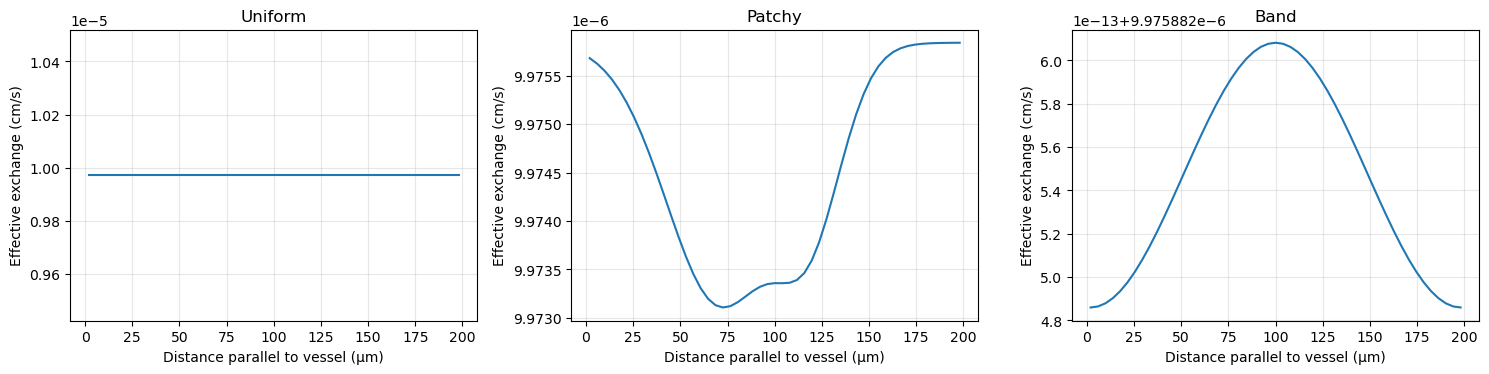

In [3]:
# ============================================================
# VISUALIZATION — EFFECTIVE VASCULAR EXCHANGE
# ============================================================

fig, axes = plt.subplots(
    1, len(P_eff_fields),
    figsize=(5 * len(P_eff_fields), 4)
)

if len(P_eff_fields) == 1:
    axes = [axes]

for ax, (name, P_eff) in zip(axes, P_eff_fields.items()):

    ax.plot(y * 1e4, P_eff)

    ax.set_title(f"{name}")
    ax.set_xlabel("Distance parallel to vessel (μm)")
    ax.set_ylabel("Effective exchange (cm/s)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()